# Gabarito — Semelhança de Triângulos e Potência de Ponto

Este notebook traz a resolução comentada dos exercícios de [`0415a_semelhanca_de_triangulos_e_potencia_de_ponto.ipynb`](0415a_semelhanca_de_triangulos_e_potencia_de_ponto.ipynb).

⚠️ **Antes de olhar aqui:** tente resolver os exercícios sozinho no notebook original e use as células de verificação (`assert`) para conferir sua resposta. Volte a este gabarito só depois de tentar — ou se travar de verdade em algum passo.

In [ ]:
# Imports necessários para os exercícios abaixo
import math
from itertools import permutations

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.patches import Arc, Circle, Polygon, Rectangle, Wedge

# Paleta de cores Nord
NORD_FUNDO = "#2E3440"
NORD_PAINEL = "#3B4252"
NORD_LINHA = "#4C566A"
NORD_TEXTO = "#ECEFF4"
NORD_TEXTO_SEC = "#D8DEE9"
COR_PONTO = "#88C0D0"
COR_DESTAQUE = "#A3BE8C"
COR_ALERTA = "#BF616A"
COR_SECUNDARIA = "#81A1C1"
COR_EXTRA = "#B48EAD"
COR_AVISO = "#EBCB8B"


def estilizar_eixo(ax) -> None:
    """Aplica o estilo Nord padrão a um eixo do matplotlib."""
    ax.set_facecolor(NORD_FUNDO)
    ax.tick_params(colors=NORD_TEXTO_SEC)
    for spine in ax.spines.values():
        spine.set_color(NORD_LINHA)
    ax.grid(color=NORD_LINHA, linewidth=0.5, alpha=0.5)


# Ferramentas do notebook principal (reconstruídas aqui).

def preparar_eixo(ax, pontos, margem: float = 0.8) -> None:
    """Deixa o eixo pronto para desenhos de geometria (estilo Nord, sem grade, sem números,
    escala igual) e enquadra todos os `pontos` com uma margem em volta."""
    estilizar_eixo(ax)
    ax.grid(False)
    xs = [p[0] for p in pontos]
    ys = [p[1] for p in pontos]
    ax.set_xlim(min(xs) - margem, max(xs) + margem)
    ax.set_ylim(min(ys) - margem, max(ys) + margem)
    ax.set_aspect("equal")
    ax.set_xticks([])
    ax.set_yticks([])


def direcao(angulo_graus: float) -> np.ndarray:
    """Vetor de tamanho 1 apontando na direção dada, em graus, a partir da horizontal (sentido anti-horário).

    (cos e sin vêm da Trigonometria, módulo 05; aqui só servem para apontar na direção certa.)
    """
    rad = math.radians(angulo_graus)
    return np.array([math.cos(rad), math.sin(rad)])


def direcao_de(origem, destino) -> float:
    """Direção, em graus, em que `destino` está quando visto de `origem`."""
    return math.degrees(math.atan2(destino[1] - origem[1], destino[0] - origem[0]))


def medir_angulo(vertice, P, Q) -> float:
    """Transferidor digital: medida, em graus, do ângulo com vértice em `vertice`
    formado pelas semirretas que passam por P e por Q (resultado entre 0° e 180°)."""
    u = np.subtract(P, vertice)
    v = np.subtract(Q, vertice)
    cosseno = np.dot(u, v) / (np.linalg.norm(u) * np.linalg.norm(v))
    return math.degrees(math.acos(np.clip(cosseno, -1, 1)))


def cruzamento(P, inclinacao_1: float, Q, inclinacao_2: float):
    """Ponto em que a reta que passa por P (com a inclinação `inclinacao_1`, em graus) cruza a reta
    que passa por Q (com a inclinação `inclinacao_2`). Devolve None se as duas retas tiverem a mesma
    direção, porque aí elas não se cruzam num ponto só.

    Por trás, é um sistema linear 2×2 (módulo 03): P + t·u = Q + k·v, com incógnitas t e k.
    """
    matriz = np.column_stack([direcao(inclinacao_1), -direcao(inclinacao_2)])
    if abs(np.linalg.det(matriz)) < 1e-12:
        return None
    t, _ = np.linalg.solve(matriz, np.subtract(Q, P))
    return np.array(P, dtype=float) + t * direcao(inclinacao_1)


def cruzamento_das_retas(A, B, C, D):
    """Ponto em que a reta AB cruza a reta CD (None se forem paralelas)."""
    return cruzamento(A, direcao_de(A, B), C, direcao_de(C, D))


def ponto_medio(P, Q) -> np.ndarray:
    """Ponto médio do segmento PQ: a média das coordenadas (0402a)."""
    return (np.asarray(P, dtype=float) + np.asarray(Q, dtype=float)) / 2


def divide_segmento(A, B, m: float, n: float) -> np.ndarray:
    """Ponto P do segmento AB tal que AP / PB = m / n: P anda m / (m + n) do caminho de A até B (0414a)."""
    A, B = np.asarray(A, dtype=float), np.asarray(B, dtype=float)
    return A + m / (m + n) * (B - A)


def iguais(x: float, y: float) -> bool:
    """Compara duas medidas com uma tolerância pequena (as contas com float têm arredondamentos)."""
    return math.isclose(x, y, rel_tol=1e-9, abs_tol=1e-6)


def produto_vetorial(u, v) -> float:
    """Produto vetorial de dois vetores do plano, u_x·v_y − u_y·v_x: a "multiplicação cruzada" de 0401a.
    Ele é zero exatamente quando u e v têm a mesma direção."""
    return float(u[0] * v[1] - u[1] * v[0])


def sao_paralelos(P, Q, R, S) -> bool:
    """True se as retas PQ e RS são paralelas (ou coincidentes), pelo produto vetorial das direções (0414a)."""
    u, v = np.subtract(Q, P), np.subtract(S, R)
    return abs(produto_vetorial(u, v)) <= 1e-9 * np.linalg.norm(u) * np.linalg.norm(v)


def desenhar_ponto(ax, p, nome: str = "", cor: str = COR_AVISO, deslocamento=(0.12, 0.15),
                   tamanho_fonte: int = 13) -> None:
    """Desenha um ponto com seu nome (letra maiúscula) ao lado."""
    ax.plot(*p, "o", color=cor, markersize=7, zorder=6)
    if nome:
        ax.text(p[0] + deslocamento[0], p[1] + deslocamento[1], nome, color=NORD_TEXTO, fontsize=tamanho_fonte,
                fontweight="bold", zorder=7)


def desenhar_reta(ax, P, Q, cor: str = COR_SECUNDARIA, estilo: str = "-", largura: float = 2.0,
                  alpha: float = 0.9) -> None:
    """Desenha a reta inteira que passa por P e por Q (até a borda do gráfico)."""
    ax.axline(tuple(np.asarray(P, dtype=float)), tuple(np.asarray(Q, dtype=float)), color=cor,
              linestyle=estilo, lw=largura, alpha=alpha, zorder=2)


def desenhar_segmento(ax, P, Q, cor: str = NORD_TEXTO, largura: float = 3.0, estilo: str = "-",
                      alpha: float = 1.0, zorder: int = 5) -> None:
    """Desenha o segmento PQ (só o pedaço entre P e Q)."""
    ax.plot(*zip(P, Q), color=cor, lw=largura, linestyle=estilo, alpha=alpha, zorder=zorder,
            solid_capstyle="round")


def desenhar_setor(ax, vertice, inicio: float, abertura: float, raio: float = 0.5, cor: str = COR_PONTO,
                   rotulo: str | None = None, marcar_reto: bool = True, raio_rotulo: float | None = None,
                   tamanho_fonte: int = 11) -> None:
    """Pinta o ângulo com vértice em `vertice` que começa na direção `inicio` e gira `abertura`
    graus no sentido anti-horário. O ângulo reto ganha o quadradinho no lugar do arco."""
    v = np.array(vertice, dtype=float)
    if marcar_reto and math.isclose(abertura, 90, abs_tol=1e-6):
        lado = 0.6 * raio
        canto = [v, v + lado * direcao(inicio), v + lado * (direcao(inicio) + direcao(inicio + 90)),
                 v + lado * direcao(inicio + 90)]
        ax.add_patch(Polygon(canto, closed=True, facecolor=cor, alpha=0.35, edgecolor=cor, lw=2))
    else:
        ax.add_patch(Wedge(v, raio, inicio, inicio + abertura, facecolor=cor, alpha=0.3, edgecolor="none"))
        ax.add_patch(Arc(v, 2 * raio, 2 * raio, theta1=inicio, theta2=inicio + abertura, color=cor, lw=2))
    if rotulo:
        distancia_rotulo = 1.6 * raio if raio_rotulo is None else raio_rotulo
        posicao = v + distancia_rotulo * direcao(inicio + abertura / 2)
        ax.text(*posicao, rotulo, color=cor, fontsize=tamanho_fonte, ha="center", va="center", fontweight="bold")


def desenhar_arco(ax, vertice, p, q, **opcoes) -> None:
    """Marca o ângulo de vértice `vertice` formado pelas semirretas que passam por p e por q
    (sempre a abertura menor, entre 0° e 180°). Aceita as mesmas opções de `desenhar_setor`."""
    inicio = direcao_de(vertice, p) % 360
    abertura = (direcao_de(vertice, q) - inicio) % 360
    if abertura > 180:
        inicio, abertura = direcao_de(vertice, q) % 360, 360 - abertura
    desenhar_setor(ax, vertice, inicio, abertura, **opcoes)


def marcar_congruentes(ax, P, Q, tracos: int = 1, cor: str = NORD_TEXTO, tamanho: float = 0.16) -> None:
    """Tracinhos no meio do segmento PQ: a marca de segmentos congruentes (0402a)."""
    P, Q = np.asarray(P, dtype=float), np.asarray(Q, dtype=float)
    u = (Q - P) / np.linalg.norm(Q - P)
    normal = np.array([-u[1], u[0]])
    meio = (P + Q) / 2
    for k in range(tracos):
        centro_traco = meio + (k - (tracos - 1) / 2) * 0.12 * u
        ax.plot(*zip(centro_traco - tamanho * normal, centro_traco + tamanho * normal), color=cor, lw=2,
                zorder=6)


def rotular_fora(ax, P, texto: str, centro, cor: str = NORD_TEXTO, distancia: float = 0.35,
                 tamanho: int = 12) -> None:
    """Escreve `texto` perto do ponto P, afastado do `centro` (para não ficar em cima da figura)."""
    P = np.asarray(P, dtype=float)
    afastar = P - np.asarray(centro, dtype=float)
    afastar = afastar / np.linalg.norm(afastar) if np.linalg.norm(afastar) > 0 else np.array([0.0, 1.0])
    ax.text(*(P + distancia * afastar), texto, color=cor, fontsize=tamanho, fontweight="bold",
            ha="center", va="center", zorder=7)


def rotular_segmento(ax, P, Q, texto: str, cor: str = NORD_TEXTO, distancia: float = 0.35, longe_de=None,
                     tamanho: int = 11) -> None:
    """Escreve `texto` ao lado do meio do segmento PQ, afastado `distancia` na direção perpendicular a ele.
    Se `longe_de` for um ponto, o texto vai para o lado do segmento oposto a esse ponto."""
    P, Q = np.asarray(P, dtype=float), np.asarray(Q, dtype=float)
    u = (Q - P) / np.linalg.norm(Q - P)
    normal = np.array([-u[1], u[0]])
    meio = (P + Q) / 2
    if longe_de is not None and np.dot(meio - np.asarray(longe_de, dtype=float), normal) < 0:
        normal = -normal
    ax.text(*(meio + distancia * normal), texto, color=cor, fontsize=tamanho, fontweight="bold",
            ha="center", va="center", zorder=7)


def escrever_checklist(ax, itens, titulo: str = "") -> None:
    """Painel de texto com uma linha por item (texto, ok): ✓ verde quando vale, ✗ vermelho quando não (0410a)."""
    ax.set_facecolor(NORD_FUNDO)
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.axis("off")
    if titulo:
        ax.text(0.0, 0.97, titulo, color=NORD_TEXTO, fontsize=12, fontweight="bold", va="top")
    passo = min(0.13, 0.85 / max(len(itens), 1))
    for k, (texto, ok) in enumerate(itens):
        ax.text(0.0, 0.84 - k * passo, f"{'✓' if ok else '✗'}  {texto}", color=COR_DESTAQUE if ok else COR_ALERTA,
                fontsize=11, va="top")


def desenhar_circunferencia(ax, O, r: float, cor: str = COR_PONTO, estilo: str = "-",
                            largura: float = 2.5, preencher: bool = False, opacidade: float = 0.15) -> None:
    """Desenha a circunferência de centro O e raio r (a linha). Com `preencher=True`, pinta também a
    região interna: o círculo (0412a)."""
    O = tuple(np.asarray(O, dtype=float))
    if preencher:
        ax.add_patch(Circle(O, r, facecolor=cor, alpha=opacidade, edgecolor="none", zorder=1))
    ax.add_patch(Circle(O, r, fill=False, edgecolor=cor, lw=largura, linestyle=estilo, zorder=3))


# Ferramentas novas deste notebook
COR_T1 = COR_PONTO  # preenchimento do primeiro triângulo de um par
COR_T2 = "#D08770"  # preenchimento do segundo triângulo do par
COR_CIRCULO = COR_SECUNDARIA  # circunferências
# Uma cor por par de vértices homólogos: A e A' amarelos, B e B' verdes, C e C' roxos. O lado oposto a um
# vértice herda a cor dele (lados homólogos são os opostos a ângulos congruentes).
CORES_VERTICES = (COR_AVISO, COR_DESTAQUE, COR_EXTRA)
# Cores fixas dos produtos da potência de ponto: PA·PB amarelo, PC·PD verde, PT² roxo
COR_PA_PB, COR_PC_PD, COR_PT = COR_AVISO, COR_DESTAQUE, COR_EXTRA


def lados(t) -> tuple[float, float, float]:
    """Medidas (a, b, c) dos lados do triângulo t = (A, B, C), na convenção de 0404a: a = BC é oposto a A,
    b = CA é oposto a B e c = AB é oposto a C."""
    A, B, C = t
    return math.dist(B, C), math.dist(C, A), math.dist(A, B)


def angulos(t) -> tuple[float, float, float]:
    """Medidas, em graus, dos ângulos internos (Â, B̂, Ĉ) do triângulo t = (A, B, C)."""
    A, B, C = t
    return medir_angulo(A, B, C), medir_angulo(B, C, A), medir_angulo(C, A, B)


def area_triangulo(t) -> float:
    """Área do triângulo t: metade do |produto vetorial| de AB e AC. É o "base × altura ÷ 2" escrito com
    coordenadas (as áreas ganham notebook próprio mais adiante no módulo)."""
    A, B, C = (np.asarray(p, dtype=float) for p in t)
    return abs(produto_vetorial(B - A, C - A)) / 2


def triangulo_por_lados(a: float, b: float, c: float):
    """Triângulo (A, B, C) com BC = a, CA = b e AB = c: A na origem, B sobre o eixo x e C no cruzamento das
    circunferências λ(A, b) e λ(B, a). Subtraindo as duas equações, sai x = (b² + c² − a²) / (2c).
    Devolve None se as medidas não formam triângulo (desigualdade triangular, 0404a)."""
    if not abs(b - c) < a < b + c:
        return None
    x = (b**2 + c**2 - a**2) / (2 * c)
    y = math.sqrt(b**2 - x**2)
    return [np.array([0.0, 0.0]), np.array([c, 0.0]), np.array([x, y])]


def desenhar_triangulo(ax, t, nomes=("A", "B", "C"), cores=CORES_VERTICES, cor_preenchimento: str = COR_T1,
                       marcar_angulos: bool = True, raio_angulo: float = 0.45, rotular_lados: bool = False,
                       tamanho: int = 13, opacidade: float = 0.15, distancia_nome: float = 0.4) -> None:
    """Desenha o triângulo t: cada vértice, o seu ângulo e o lado OPOSTO a ele na mesma cor (uma cor por
    par de vértices homólogos). Com `rotular_lados=True`, escreve a medida de cada lado."""
    t = [np.asarray(p, dtype=float) for p in t]
    centro = sum(t) / 3
    ax.add_patch(Polygon(t, closed=True, facecolor=cor_preenchimento, alpha=opacidade, edgecolor="none", zorder=1))
    for i in range(3):
        P, Q = t[(i + 1) % 3], t[(i + 2) % 3]
        desenhar_segmento(ax, P, Q, cor=cores[i], largura=3, zorder=4)
        if rotular_lados:
            rotular_segmento(ax, P, Q, f"{math.dist(P, Q):.2f}", cor=cores[i], distancia=0.38, longe_de=centro,
                             tamanho=10)
    for i in range(3):
        if marcar_angulos:
            desenhar_arco(ax, t[i], t[(i + 1) % 3], t[(i + 2) % 3], raio=raio_angulo, cor=cores[i])
        desenhar_ponto(ax, t[i], cor=cores[i])
        rotular_fora(ax, t[i], nomes[i], centro, distancia=distancia_nome, tamanho=tamanho)


def intersecoes_reta_circunferencia(O, r: float, P, angulo: float) -> list[np.ndarray]:
    """Pontos em que a reta que passa por P, na direção `angulo` (em graus), corta a circunferência λ(O, r).

    Os pontos da reta são X = P + t·u, com u = direcao(angulo). X está na circunferência quando |X − O|² = r²,
    o que dá a equação do 2º grau t² + 2(u·w)·t + (|w|² − r²) = 0, com w = P − O (0108a e 0109a).
    Devolve a lista dos pontos (0, 1 ou 2), em ordem crescente de t.
    """
    u = direcao(angulo)
    w = np.subtract(P, O).astype(float)
    b = 2 * float(np.dot(u, w))
    c = float(np.dot(w, w)) - r**2
    delta = b**2 - 4 * c
    if delta < -1e-9:
        return []
    if abs(delta) <= 1e-9:
        raizes = [-b / 2]
    else:
        raizes = [(-b - math.sqrt(delta)) / 2, (-b + math.sqrt(delta)) / 2]
    return [np.asarray(P, dtype=float) + t * u for t in raizes]


def transformar(t, k: float = 1.0, rotacao: float = 0.0, refletir: bool = False, destino=(0.0, 0.0)):
    """Cópia do triângulo t ampliada (ou reduzida) pelo fator k, girada `rotacao` graus e, se pedido, refletida
    num espelho vertical, com o centro (a média dos vértices) levado até `destino`. São os movimentos de 0405a
    (deslizar, girar, refletir) mais a mudança de escala. A ordem dos vértices é mantida."""
    pontos = np.array(t, dtype=float)
    pontos = pontos - pontos.mean(axis=0)
    if refletir:
        pontos[:, 0] = -pontos[:, 0]
    giro = np.column_stack([direcao(rotacao), direcao(rotacao + 90)])  # matriz de rotação (módulo 03)
    pontos = k * pontos @ giro.T
    return [p + np.asarray(destino, dtype=float) for p in pontos]


def semelhantes(t1, t2):
    """Testa se os triângulos t1 e t2 são semelhantes. Experimenta as 6 correspondências possíveis entre os
    vértices (como em 0405a) e, na primeira que funcionar (ângulos correspondentes iguais E lados
    correspondentes proporcionais), devolve (ordem, k). A `ordem` é uma tupla como (2, 0, 1): o vértice 0 de t1
    corresponde ao vértice 2 de t2, o vértice 1 ao vértice 0, e o vértice 2 ao vértice 1. Devolve None se
    nenhuma correspondência funcionar."""
    lados_1, angulos_1 = lados(t1), angulos(t1)
    for ordem in permutations(range(3)):
        t2_reordenado = [t2[i] for i in ordem]
        razoes = [l2 / l1 for l1, l2 in zip(lados_1, lados(t2_reordenado))]
        lados_ok = all(iguais(razao, razoes[0]) for razao in razoes)
        angulos_ok = all(math.isclose(x, y, abs_tol=1e-6) for x, y in zip(angulos_1, angulos(t2_reordenado)))
        if lados_ok and angulos_ok:
            return ordem, razoes[0]
    return None


def descrever_correspondencia(ordem, nomes_1: str = "ABC", nomes_2=("A'", "B'", "C'")) -> str:
    """Texto como 'A↔F, B↔D, C↔E' a partir da `ordem` devolvida por `semelhantes`."""
    return ", ".join(f"{nomes_1[i]}↔{nomes_2[ordem[i]]}" for i in range(3))


def criterios_semelhanca(t1, t2) -> list[str]:
    """Lista dos critérios de semelhança ("AA", "LAL", "LLL") satisfeitos pelos triângulos t1 = (A, B, C) e
    t2 = (A', B', C'), com a correspondência dada pela ORDEM dos vértices (A↔A', B↔B', C↔C')."""
    angulos_iguais = [math.isclose(x, y, abs_tol=1e-6) for x, y in zip(angulos(t1), angulos(t2))]
    razoes = [y / x for x, y in zip(lados(t1), lados(t2))]  # razoes[i]: lado oposto ao vértice i
    criterios = []
    if sum(angulos_iguais) >= 2:
        criterios.append("AA")
    for i in range(3):
        # os dois lados que saem do vértice i são os opostos aos outros dois vértices
        j, m = [x for x in range(3) if x != i]
        if angulos_iguais[i] and iguais(razoes[j], razoes[m]):
            criterios.append("LAL")
            break
    if iguais(razoes[0], razoes[1]) and iguais(razoes[1], razoes[2]):
        criterios.append("LLL")
    return criterios


def triangulo_AA(angulo_A: float, angulo_B: float, AB: float):
    """Triângulo com os ângulos Â e B̂ dados e o lado AB: C é o cruzamento dos lados que saem de A e de B."""
    A, B = np.array([0.0, 0.0]), np.array([AB, 0.0])
    return [A, B, cruzamento(A, angulo_A, B, 180 - angulo_B)]


def triangulo_LAL(AB: float, AC: float, angulo_A: float):
    """Triângulo com os lados AB e AC e o ângulo Â entre eles."""
    A = np.array([0.0, 0.0])
    return [A, np.array([AB, 0.0]), A + AC * direcao(angulo_A)]


def potencia(O, r: float, P) -> float:
    """Potência do ponto P em relação à circunferência λ(O, r): OP² − r²."""
    return math.dist(O, P) ** 2 - r**2


def pontos_de_tangencia(O, r: float, P):
    """Pontos T1 e T2 em que as tangentes traçadas por P tocam λ(O, r): o cruzamento de λ(O, r) com a
    circunferência de diâmetro OP (0412a). Devolve None se P não for exterior."""
    O, P = np.asarray(O, dtype=float), np.asarray(P, dtype=float)
    d = math.dist(O, P)
    if d <= r + 1e-9:
        return None
    u = (P - O) / d
    normal = np.array([-u[1], u[0]])
    a = r**2 / d  # distância de O até a corda T1T2 (subtraindo as equações das duas circunferências)
    h = math.sqrt(r**2 - a**2)
    return O + a * u + h * normal, O + a * u - h * normal

## Básico

**Exercício 1.** Reconhecer semelhança, usar a razão $k$ e o teorema fundamental.

In [2]:
# (a) Menor com menor, médio com médio, maior com maior: 9/3 = 12/4 = 15/5 = 3
semelhantes_ex1a = iguais(9 / 3, 12 / 4) and iguais(12 / 4, 15 / 5)  # True (critério LLL)
k_ex1a = 9 / 3  # 3
razao_areas_ex1a = k_ex1a**2  # as áreas ficam multiplicadas por k² = 9

# (b) △ABC ~ △DEF: AB↔DE, BC↔EF, CA↔FD. A razão sai do par conhecido: k = DE/AB = 9/6 = 1,5
k_ex1b = 9 / 6
EF_ex1b = k_ex1b * 8  # 12
FD_ex1b = k_ex1b * 10  # 15

# (c) e (d): o terceiro ângulo sai da soma 180° (0404a); com dois ângulos iguais, o critério AA garante a semelhança
angulos_1c, angulos_2c = sorted([40, 75, 180 - 40 - 75]), sorted([75, 65, 180 - 75 - 65])  # [40, 65, 75] nos dois
semelhantes_ex1c = angulos_1c == angulos_2c  # True
angulos_1d, angulos_2d = sorted([50, 60, 180 - 50 - 60]), sorted([50, 80, 180 - 50 - 80])  # [50, 60, 70] e [50, 50, 80]
semelhantes_ex1d = angulos_1d == angulos_2d  # False: só o 50° coincide

# (e) Teorema fundamental: DE/BC = AD/AB, com o lado INTEIRO AB = 3 + 6 = 9
DE_ex1e = 12 * 3 / (3 + 6)  # 4

print(semelhantes_ex1a, k_ex1a, razao_areas_ex1a, EF_ex1b, FD_ex1b, semelhantes_ex1c, semelhantes_ex1d, DE_ex1e)
print("ângulos (c):", angulos_1c, angulos_2c, "  ângulos (d):", angulos_1d, angulos_2d)

# Conferência geométrica do item (b): construímos os dois triângulos pelos lados e pedimos a correspondência
t_ABC, t_DEF = triangulo_por_lados(8, 10, 6), triangulo_por_lados(EF_ex1b, FD_ex1b, 9)
ordem, k = semelhantes(t_ABC, t_DEF)
print(f"(b) correspondência: {descrever_correspondencia(ordem, 'ABC', 'DEF')},  k = {k:g}")

True 3.0 9.0 12.0 15.0 True False 4.0
ângulos (c): [40, 65, 75] [40, 65, 75]   ângulos (d): [50, 60, 70] [50, 50, 80]
(b) correspondência: A↔D, B↔E, C↔F,  k = 1.5


No item (e), o erro mais comum é usar $\frac{AD}{DB} = \frac{3}{6}$ e obter $DE = 6$. A razão $\frac{AD}{DB}$ é a de Tales e não envolve $\overline{DE}$; o segmento paralelo se compara com o lado inteiro.

**Exercício 2.** Sombras e potência de ponto com números inteiros.

In [3]:
# (a) e (b): mesmo instante ⇒ mesmo ângulo do Sol ⇒ triângulos semelhantes (AA) ⇒ altura/sombra igual nos dois
altura_poste_ex2a = 1.5 / 2 * 10  # 7,5 m
altura_arvore_ex2b = 1.60 / 1.20 * 9  # 12 m

# (c) Duas cordas: PA · PB = PC · PD  →  4 · 6 = 3 · PD
PD_ex2c = 4 * 6 / 3  # 8

# (d) Duas secantes: PA · PB = PC · PD  →  4 · 9 = 3 · PD; a corda CD é o pedaço de PD depois de C
PD_ex2d = 4 * 9 / 3  # 12
CD_ex2d = PD_ex2d - 3  # 9

# (e) Tangente e secante: PT² = PA · PB = 4 · 9 = 36 (PB é o segmento inteiro, não a corda AB = 5)
PT_ex2e = math.sqrt(4 * 9)  # 6

# (f) Pot(P) = OP² − r² = 100 − 36 = 64, e PA · PB = 64  →  PB = 64/4
pot_ex2f = 10**2 - 6**2
PB_ex2f = pot_ex2f / 4  # 16

print(altura_poste_ex2a, altura_arvore_ex2b, PD_ex2c, PD_ex2d, CD_ex2d, PT_ex2e, pot_ex2f, PB_ex2f)

# Conferência do item (f) com a geometria: P a 10 cm do centro e a reta que vai de P na direção do centro (180°)
O_f, r_f, P_f = np.array([0.0, 0.0]), 6.0, np.array([10.0, 0.0])
X1, X2 = intersecoes_reta_circunferencia(O_f, r_f, P_f, 180)
print(f"(f) PA = {math.dist(P_f, X1):g} e PB = {math.dist(P_f, X2):g}; PA · PB = {math.dist(P_f, X1) * math.dist(P_f, X2):g}")

7.5 12.000000000000002 8.0 12.0 9.0 6.0 64 16.0
(f) PA = 4 e PB = 16; PA · PB = 64


Repare no item (f): a corda $\overline{AB}$ mede $16 - 4 = 12$ cm, que é exatamente o **diâmetro**. Não é coincidência: a única reta por $P$ cujo ponto mais próximo fica a $d - r = 10 - 6 = 4$ cm é a que passa pelo centro, a reta da "unificação" da seção 5.

## Intermediário

**Exercício 3.** Implementar `semelhantes` e `criterios_semelhanca` (e testar com contraexemplos).

In [4]:
def semelhantes_ex3(t1, t2):
    # Para cada uma das 6 correspondências, reordena os vértices de t2 e confere a definição
    for ordem in permutations(range(3)):
        t2_reordenado = [t2[i] for i in ordem]
        razoes = [l2 / l1 for l1, l2 in zip(lados(t1), lados(t2_reordenado))]
        lados_ok = iguais(razoes[0], razoes[1]) and iguais(razoes[1], razoes[2])
        angulos_ok = all(math.isclose(x, y, abs_tol=1e-6) for x, y in zip(angulos(t1), angulos(t2_reordenado)))
        if lados_ok and angulos_ok:
            return razoes[0]
    return None


def criterios_ex3(t1, t2) -> list:
    angulos_iguais = [math.isclose(x, y, abs_tol=1e-6) for x, y in zip(angulos(t1), angulos(t2))]
    razoes = [y / x for x, y in zip(lados(t1), lados(t2))]  # razoes[i]: lado oposto ao vértice i
    criterios = []
    if sum(angulos_iguais) >= 2:  # dois ângulos (o terceiro vem de graça, pela soma 180°)
        criterios.append("AA")
    # LAL: o ângulo no vértice i fica ENTRE os lados que saem de i, que são os opostos aos outros dois vértices
    if any(angulos_iguais[i] and iguais(*[razoes[j] for j in range(3) if j != i]) for i in range(3)):
        criterios.append("LAL")
    if iguais(razoes[0], razoes[1]) and iguais(razoes[1], razoes[2]):
        criterios.append("LLL")
    return criterios


# (c) O contraexemplo LLA da seção 3, reconstruído
B_lla = np.array([0.0, 0.0])
A_lla = B_lla + 6 * direcao(30)
C1_lla, C2_lla = intersecoes_reta_circunferencia(A_lla, 4, B_lla, 0)
t1_lla, t2_lla = [A_lla, B_lla, C1_lla], transformar([A_lla, B_lla, C2_lla], k=1.5)
criterios_lla_ex3 = criterios_ex3(t1_lla, t2_lla)

print(semelhantes_ex3(triangulo_por_lados(3, 4, 5), triangulo_por_lados(12, 9, 15)), criterios_lla_ex3)
print("razões a'/a, b'/b, c'/c no LLA:", [round(y / x, 4) for x, y in zip(lados(t1_lla), lados(t2_lla))])
print("ângulos no LLA:", [round(a, 2) for a in angulos(t1_lla)], [round(a, 2) for a in angulos(t2_lla)])

3.0000000000000004 []
razões a'/a, b'/b, c'/c no LLA: [4.6122, 1.5, 1.5]
ângulos no LLA: [18.59, 30.0, 131.41] [101.41, 30.0, 48.59]


No contraexemplo LLA, $\frac{b'}{b} = \frac{c'}{c} = 1{,}5$ (os lados $\overline{CA}$ e $\overline{AB}$) e $\hat{B} = \hat{B'} = 30°$. Mas o ângulo **entre** $\overline{CA}$ e $\overline{AB}$ é o $\hat{A}$, e não o $\hat{B}$: por isso não é LAL. Os ângulos em $A$ e em $C$ são diferentes nos dois triângulos (um tem $C$ agudo e o outro, obtuso).

**Exercício 4.** Potência de ponto verificada com pontos e retas sorteados.

In [5]:
def potencia_ex4(O, r: float, P) -> float:
    return math.dist(O, P) ** 2 - r**2


def produto_ex4(O, r: float, P, angulo: float):
    pontos = intersecoes_reta_circunferencia(O, r, P, angulo)
    if len(pontos) != 2:
        return None  # a reta não corta (ou só toca) a circunferência
    return math.dist(P, pontos[0]) * math.dist(P, pontos[1])


gerador_ex4 = np.random.default_rng(15)
testes_ex4, maior_erro_ex4, maior_erro_tangente_ex4 = 0, 0.0, 0.0
for _ in range(300):
    O = gerador_ex4.uniform(-3, 3, 2)
    r = gerador_ex4.uniform(1, 4)
    P = gerador_ex4.uniform(-8, 8, 2)
    angulo = gerador_ex4.uniform(0, 180)
    produto = produto_ex4(O, r, P, angulo)
    if produto is None:
        continue
    testes_ex4 += 1
    pot = potencia_ex4(O, r, P)
    maior_erro_ex4 = max(maior_erro_ex4, abs(produto - abs(pot)))  # o produto de comprimentos usa |Pot|
    if pot > 0:  # P exterior: também há tangente
        T, _ = pontos_de_tangencia(O, r, P)
        maior_erro_tangente_ex4 = max(maior_erro_tangente_ex4, abs(math.dist(P, T) ** 2 - pot))

print(testes_ex4, maior_erro_ex4, maior_erro_tangente_ex4)

102 2.842170943040401e-14 5.684341886080802e-14


Os erros ficam na casa de $10^{-13}$ ou menos: são só os arredondamentos do `float`. Em centenas de situações sorteadas (pontos dentro e fora, retas em todas as direções), o produto $PA \cdot PB$ nunca saiu de $|OP^2 - r^2|$.

**Exercício 5.** Problemas que combinam Tales, semelhança e bissetriz.

In [6]:
# (a) Teorema da bissetriz (0414a): BD/DC = AB/AC = 9/6 = 3/2 e BD + DC = 10  →  BD = 10 · 3/5, DC = 10 · 2/5
BD_ex5 = 10 * 9 / (9 + 6)  # 6
DC_ex5 = 10 * 6 / (9 + 6)  # 4

# (b) No triângulo BCA, a reta DF é paralela ao lado CA: pelo teorema fundamental, △BDF ~ △BCA (B↔B, D↔C, F↔A)
k_ex5 = BD_ex5 / 10  # 0,6
BF_ex5 = k_ex5 * 9  # BF/BA = k  →  5,4
DF_ex5 = k_ex5 * 6  # DF/CA = k  →  3,6 (este é o par que Tales sozinho não dava)

# (c) Áreas: k²
razao_areas_ex5 = k_ex5**2  # 0,36

# (d) AD/AB = DE/BC  →  x/(x + 4) = 6/10  →  10x = 6x + 24  →  x = 6
x_ex5d = 24 / 4

print(BD_ex5, DC_ex5, k_ex5, BF_ex5, DF_ex5, razao_areas_ex5, x_ex5d)

# Conferência com coordenadas: montamos o triângulo 9-6-10 e refazemos a construção
t = triangulo_por_lados(10, 6, 9)  # BC = 10, CA = 6, AB = 9
A, B, C = t
D = divide_segmento(B, C, 9, 6)  # BD : DC = AB : AC
F = cruzamento_das_retas(D, D + (A - C), A, B)  # a paralela a CA por D corta AB em F
print(f"conferência: BD = {math.dist(B, D):.4f}, BF = {math.dist(B, F):.4f}, DF = {math.dist(D, F):.4f}, "
      f"área(BDF)/área(BCA) = {area_triangulo([B, D, F]) / area_triangulo(t):.4f}")
print(f"o ângulo BAD é igual a DAC? {medir_angulo(A, B, D):.4f}° e {medir_angulo(A, D, C):.4f}°")

6.0 4.0 0.6 5.3999999999999995 3.5999999999999996 0.36 6.0
conferência: BD = 6.0000, BF = 5.4000, DF = 3.6000, área(BDF)/área(BCA) = 0.3600
o ângulo BAD é igual a DAC? 40.4718° e 40.4718°


**Exercício 6.** A demonstração do critério LLL, guiada.

['d', 'a', 'b', 'c'] True 5.531726674375732 5.531726674375731 True


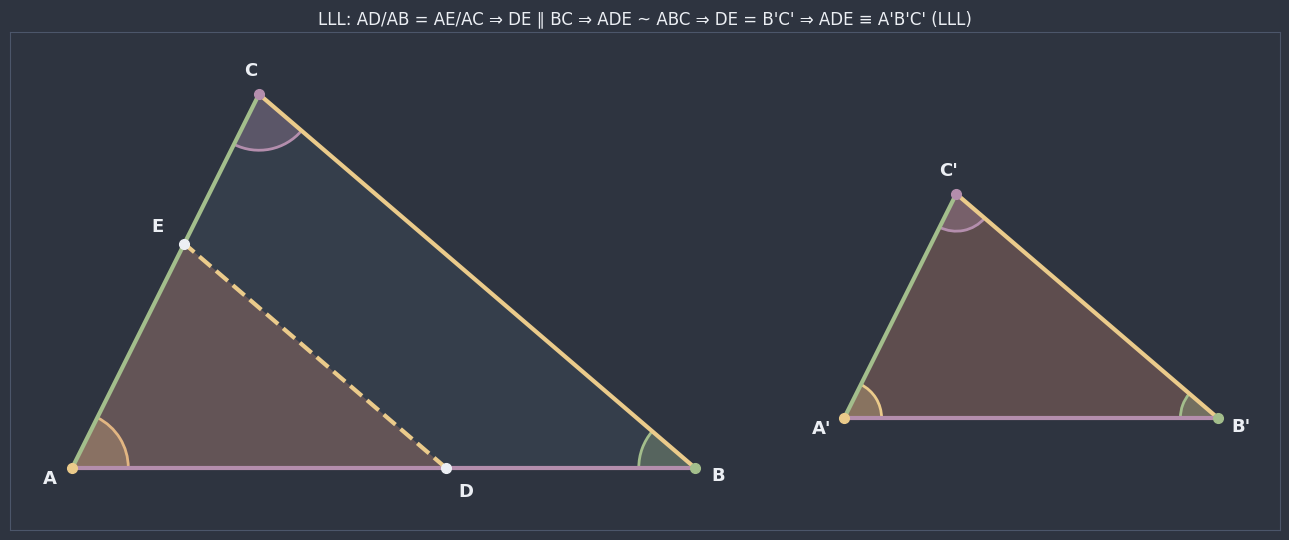

In [7]:
# (a) Passo 1: AD = A'B' e AE = A'C' (construção) e A'B'/AB = A'C'/AC = k (hipótese)        → "d"
#     Passo 2: razões iguais sobre os dois lados ⇒ DE ∥ BC: recíproca de Tales (0414a)       → "a"
#     Passo 3: DE ∥ BC ⇒ △ADE ~ △ABC, logo DE = k · BC, que é B'C' pela hipótese              → "b"
#     Passo 4: AD = A'B', AE = A'C' e DE = B'C' ⇒ △ADE ≡ △A'B'C' (caso LLL de congruência)   → "c"
justificativas_ex6 = ["d", "a", "b", "c"]

# (b) A cadeia em código
A_ex6, B_ex6, C_ex6 = np.array([0.0, 0.0]), np.array([10.0, 0.0]), np.array([3.0, 6.0])
k_ex6 = 0.6
a, b, c = lados([A_ex6, B_ex6, C_ex6])
A2, B2, C2 = triangulo_por_lados(k_ex6 * a, k_ex6 * b, k_ex6 * c)  # A'B'C', montado em outro lugar
D = A_ex6 + (math.dist(A2, B2) / math.dist(A_ex6, B_ex6)) * (B_ex6 - A_ex6)  # AD = A'B'
E = A_ex6 + (math.dist(A2, C2) / math.dist(A_ex6, C_ex6)) * (C_ex6 - A_ex6)  # AE = A'C'
paralelo_ex6 = sao_paralelos(D, E, B_ex6, C_ex6)
DE_ex6 = math.dist(D, E)
B2C2_ex6 = math.dist(B2, C2)
angulos_iguais_ex6 = all(math.isclose(x, y) for x, y in zip(angulos([A_ex6, D, E]), angulos([A2, B2, C2])))

print(justificativas_ex6, paralelo_ex6, DE_ex6, B2C2_ex6, angulos_iguais_ex6)

fig, ax = plt.subplots(figsize=(13, 6))
fig.patch.set_facecolor(NORD_FUNDO)
copia = transformar([A2, B2, C2], destino=(15, 2))
preparar_eixo(ax, [A_ex6, B_ex6, C_ex6] + copia, margem=1.0)
desenhar_triangulo(ax, [A_ex6, B_ex6, C_ex6], "ABC", cor_preenchimento=COR_T1, opacidade=0.08, raio_angulo=0.9)
desenhar_triangulo(ax, copia, ("A'", "B'", "C'"), cor_preenchimento=COR_T2, opacidade=0.3, raio_angulo=0.6)
ax.add_patch(Polygon([A_ex6, D, E], closed=True, facecolor=COR_T2, alpha=0.3, edgecolor="none"))
desenhar_segmento(ax, D, E, cor=CORES_VERTICES[0], largura=3, estilo="--")
for X, nome in ((D, "D"), (E, "E")):
    desenhar_ponto(ax, X, cor=NORD_TEXTO)
    rotular_fora(ax, X, nome, (A_ex6 + B_ex6 + C_ex6) / 3, distancia=0.5, tamanho=13)
ax.set_title("LLL: AD/AB = AE/AC ⇒ DE ∥ BC ⇒ ADE ~ ABC ⇒ DE = B'C' ⇒ ADE ≡ A'B'C' (LLL)", color=NORD_TEXTO,
             fontsize=12)
plt.tight_layout()
plt.show()

Compare com o LAL da seção 3: lá, a **congruência** vinha primeiro (passo 2) e a paralela depois; aqui, a **paralela** vem primeiro, porque só depois do teorema fundamental se sabe quanto mede $\overline{DE}$, o terceiro lado necessário para o caso LLL de congruência.

## Desafio

**Exercício 7.** Construindo $\sqrt{a \cdot b}$ com régua e compasso.

[2.0, 4.0, 6.0, 2.449489742783178, 5.999999999999999] 8.881784197001252e-16 (2.0, 2.0)


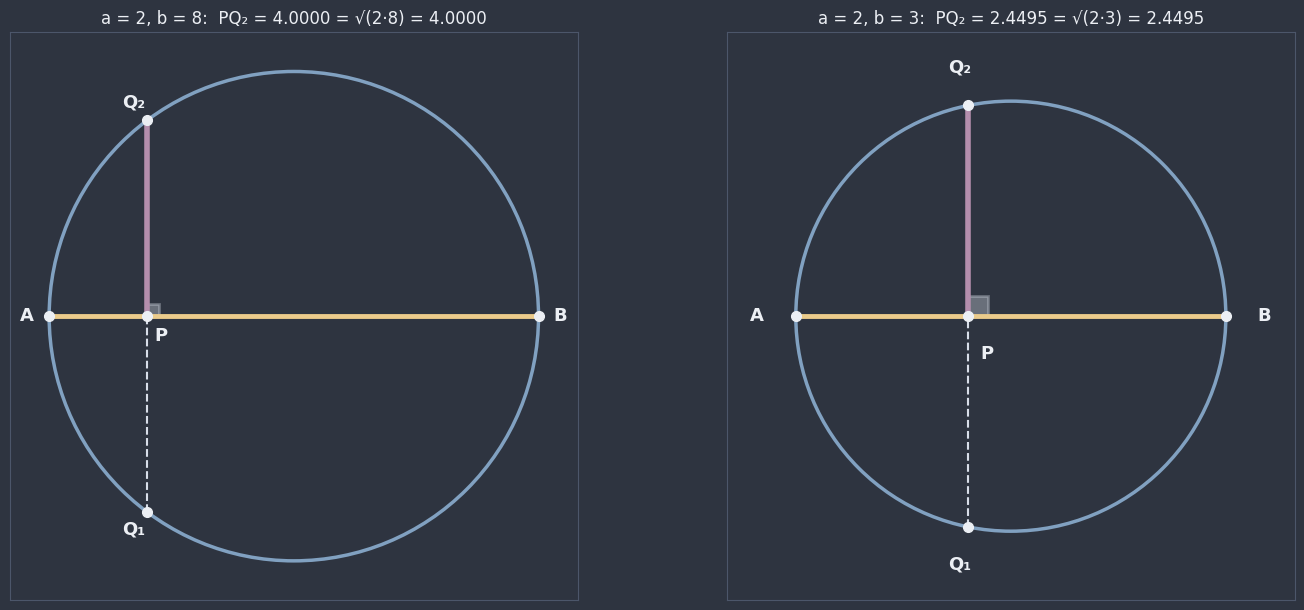

In [8]:
def media_geometrica_ex7(a: float, b: float) -> float:
    P, A, B = np.array([0.0, 0.0]), np.array([-a, 0.0]), np.array([b, 0.0])
    centro, raio = ponto_medio(A, B), (a + b) / 2  # a circunferência de diâmetro AB
    Q1, Q2 = intersecoes_reta_circunferencia(centro, raio, P, 90)  # a perpendicular a AB por P
    return math.dist(P, Q1)


pares_ex7 = [(1, 4), (2, 8), (3, 12), (2, 3), (5, 7.2)]
resultados_ex7 = [media_geometrica_ex7(a, b) for a, b in pares_ex7]
maior_erro_ex7 = max(abs(g - math.sqrt(a * b)) for g, (a, b) in zip(resultados_ex7, pares_ex7))
g = media_geometrica_ex7(2, 8)
razoes_pg_ex7 = (g / 2, 8 / g)  # (2, 2): 2, 4, 8 é uma PG de razão 2

print(resultados_ex7, maior_erro_ex7, razoes_pg_ex7)

# (d) Por que funciona: AB (diâmetro) e Q1Q2 são duas cordas que se cortam em P, então PA · PB = PQ1 · PQ2.
#     Como AB passa pelo centro e é perpendicular a Q1Q2, P é o ponto médio de Q1Q2 (0412a): PQ1 = PQ2.
#     Logo PQ1² = a · b, ou seja, PQ1 = √(a·b).
fig, eixos = plt.subplots(1, 2, figsize=(15, 6.2))
fig.patch.set_facecolor(NORD_FUNDO)
for ax, (a, b) in zip(eixos, [(2, 8), (2, 3)]):
    P, A, B = np.array([0.0, 0.0]), np.array([-a, 0.0]), np.array([b, 0.0])
    centro, raio = ponto_medio(A, B), (a + b) / 2
    Q1, Q2 = intersecoes_reta_circunferencia(centro, raio, P, 90)
    preparar_eixo(ax, [centro + (raio, raio), centro - (raio, raio)], margem=0.8)
    desenhar_circunferencia(ax, centro, raio, cor=COR_CIRCULO)
    desenhar_segmento(ax, A, B, cor=COR_PA_PB, largura=3.5)
    desenhar_segmento(ax, Q1, Q2, cor=NORD_TEXTO_SEC, largura=1.5, estilo="--")
    desenhar_segmento(ax, P, Q2, cor=COR_PT, largura=4)
    desenhar_arco(ax, P, B, Q2, raio=0.4, cor=NORD_TEXTO_SEC)
    for X, nome in ((A, "A"), (B, "B"), (Q1, "Q₁"), (Q2, "Q₂")):
        desenhar_ponto(ax, X, cor=NORD_TEXTO)
        rotular_fora(ax, X, nome, centro, distancia=0.45, tamanho=13)
    desenhar_ponto(ax, P, "P", cor=NORD_TEXTO, deslocamento=(0.15, -0.5))
    ax.set_title(f"a = {a}, b = {b}:  PQ₂ = {math.dist(P, Q2):.4f} = √({a}·{b}) = {math.sqrt(a * b):.4f}",
                 color=NORD_TEXTO, fontsize=12)
plt.tight_layout()
plt.show()

🕵️ **Para que serve:** os gregos antigos não tinham "raiz quadrada" como operação numérica, mas sabiam **construir** segmentos. Essa construção (que aparece em Euclides, para transformar um retângulo num quadrado de mesma área) é a "quadratura do retângulo": o quadrado de lado $PQ_2$ tem a mesma área que o retângulo de lados $a$ e $b$. É o modo "quadratura" do widget da seção 5, agora com régua e compasso. Com $a = 1$, a construção dá $\sqrt{b}$: **qualquer** raiz quadrada pode ser construída.

**Exercício 8.** A altura relativa à hipotenusa.

conferência do ângulo reto em A: 90.0000°
[4. 0.] 6.0 4.0 9.0 (36.0, 36.0) (['AA', 'LAL', 'LLL'], ['AA', 'LAL', 'LLL']) -36.0 0.0 3.907985046680551e-14


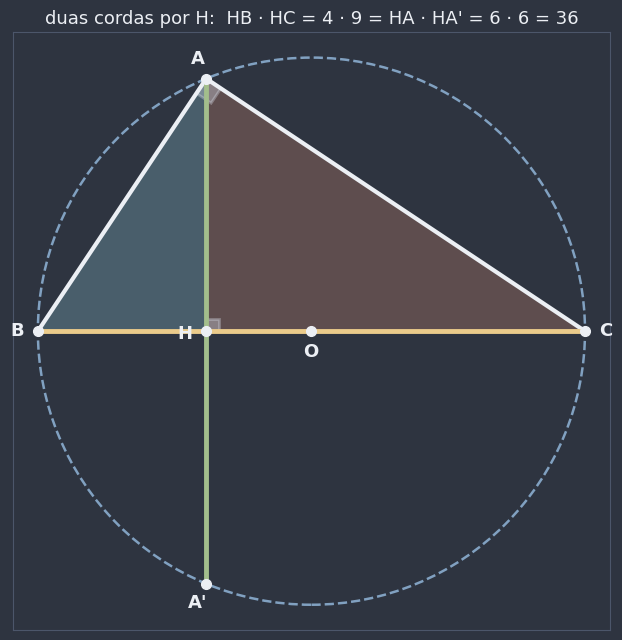

In [9]:
A_ex8, B_ex8, C_ex8 = np.array([4.0, 6.0]), np.array([0.0, 0.0]), np.array([13.0, 0.0])
print(f"conferência do ângulo reto em A: {medir_angulo(A_ex8, B_ex8, C_ex8):.4f}°")


def pe_da_altura(A, B, C) -> np.ndarray:
    """Projeção ortogonal de A sobre a reta BC (0407a)."""
    u = C - B
    return B + np.dot(A - B, u) / np.dot(u, u) * u


# (a) e (b)
H_ex8 = pe_da_altura(A_ex8, B_ex8, C_ex8)  # (4, 0)
h_ex8 = math.dist(A_ex8, H_ex8)  # 6
m_ex8 = math.dist(B_ex8, H_ex8)  # 4
n_ex8 = math.dist(H_ex8, C_ex8)  # 9
hh_mn_ex8 = (h_ex8**2, m_ex8 * n_ex8)  # (36, 36)

# (c) △ABC ~ △HBA (ângulo reto + B̂ comum) e △ABC ~ △HAC (ângulo reto + Ĉ comum)
criterios_ex8 = (criterios_semelhanca([A_ex8, B_ex8, C_ex8], [H_ex8, B_ex8, A_ex8]),
                 criterios_semelhanca([A_ex8, B_ex8, C_ex8], [H_ex8, A_ex8, C_ex8]))

# (d) A está na circunferência de diâmetro BC (ângulo reto inscrito numa semicircunferência, 0413a)
O_ex8, r_ex8 = ponto_medio(B_ex8, C_ex8), math.dist(B_ex8, C_ex8) / 2
pot_H_ex8 = potencia(O_ex8, r_ex8, H_ex8)  # 2,5² − 6,5² = −36 = −m·n
pot_A_ex8 = potencia(O_ex8, r_ex8, A_ex8)  # 0

# (e) 50 triângulos retângulos sorteados
gerador_ex8 = np.random.default_rng(8)
maior_erro_ex8 = 0.0
for _ in range(50):
    L = gerador_ex8.uniform(2, 20)
    theta = gerador_ex8.uniform(10, 170)
    B, C = np.array([0.0, 0.0]), np.array([L, 0.0])
    A = np.array([L / 2, 0.0]) + (L / 2) * direcao(theta)
    H = pe_da_altura(A, B, C)
    maior_erro_ex8 = max(maior_erro_ex8, abs(math.dist(A, H) ** 2 - math.dist(B, H) * math.dist(H, C)))

print(H_ex8, h_ex8, m_ex8, n_ex8, hh_mn_ex8, criterios_ex8, pot_H_ex8, pot_A_ex8, maior_erro_ex8)

fig, ax = plt.subplots(figsize=(11, 6.5))
fig.patch.set_facecolor(NORD_FUNDO)
A2 = 2 * H_ex8 - A_ex8  # o outro ponto da corda vertical por H
preparar_eixo(ax, [O_ex8 + (r_ex8, r_ex8), O_ex8 - (r_ex8, r_ex8)], margem=0.6)
desenhar_circunferencia(ax, O_ex8, r_ex8, cor=COR_CIRCULO, estilo="--", largura=1.8)
ax.add_patch(Polygon([H_ex8, B_ex8, A_ex8], closed=True, facecolor=COR_T1, alpha=0.3, edgecolor="none"))
ax.add_patch(Polygon([H_ex8, A_ex8, C_ex8], closed=True, facecolor=COR_T2, alpha=0.3, edgecolor="none"))
for P, Q in ((A_ex8, B_ex8), (A_ex8, C_ex8)):
    desenhar_segmento(ax, P, Q, cor=NORD_TEXTO, largura=3)
desenhar_segmento(ax, B_ex8, C_ex8, cor=COR_PA_PB, largura=3.5)
desenhar_segmento(ax, A_ex8, A2, cor=COR_PC_PD, largura=3.5)
desenhar_arco(ax, A_ex8, B_ex8, C_ex8, raio=0.7, cor=NORD_TEXTO_SEC)
desenhar_arco(ax, H_ex8, C_ex8, A_ex8, raio=0.5, cor=NORD_TEXTO_SEC)
for X, nome in ((A_ex8, "A"), (B_ex8, "B"), (C_ex8, "C"), (H_ex8, "H"), (A2, "A'"), (O_ex8, "O")):
    desenhar_ponto(ax, X, cor=NORD_TEXTO)
    rotular_fora(ax, X, nome, O_ex8 + (0.01, 0.3) if nome in "HO" else O_ex8, distancia=0.5, tamanho=13)
ax.set_title(f"duas cordas por H:  HB · HC = {m_ex8:g} · {n_ex8:g} = HA · HA' = {h_ex8:g} · {h_ex8:g} = {h_ex8**2:g}",
             color=NORD_TEXTO, fontsize=13)
plt.tight_layout()
plt.show()

A figura mostra as duas leituras de $h^2 = m \cdot n$: pela **semelhança** (os triângulos sombreados $HBA$ e $HAC$, ambos semelhantes a $ABC$, dão $\frac{h}{m} = \frac{n}{h}$) e pela **potência de ponto** (as cordas $\overline{BC}$, em amarelo, e $\overline{AA'}$, em verde, se cortam em $H$, e $HA = HA' = h$). A potência de $H$ é $-36$: negativa, porque $H$ está dentro da circunferência, e com valor absoluto $m \cdot n = h^2$.

🎯 **Para que serve:** esta é a mesma figura do Desafio 7 (a média geométrica), vista de outro ângulo: a altura relativa à hipotenusa é a **média geométrica** das projeções, $h = \sqrt{m \cdot n}$. A dedução completa desta e das outras relações métricas é o ponto de partida de 📌 Triângulos Retângulos.